In [1]:
!pip -q install sgp4 requests numpy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.1/218.1 kB 5.5 MB/s eta 0:00:00


In [3]:
import requests

url = "https://celestrak.org/NORAD/elements/gp.php?CATNR=25544&FORMAT=TLE"

response = requests.get(url, timeout=30)
response.raise_for_status()

lines = [line.strip() for line in response.text.splitlines() if line.strip()]

print("CelesTrak yanıtı:")
print(response.text)

if len(lines) < 3 or not lines[1].startswith("1 ") or not lines[2].startswith("2 "):
    raise ValueError("Beklenen TLE biçiminde veri gelmedi. Yanıtı kontrol et.")

satellite_name = lines[0]
tle_line1 = lines[1]
tle_line2 = lines[2]

print("\nUydu adı:", satellite_name)
print("TLE satır1:", tle_line1)
print("TLE satır2:", tle_line2)

CelesTrak yanıtı:
ISS (ZARYA)             
1 25544U 98067A   26281.98258931  .00005946  00000+0  11685-3 0  9991
2 25544  51.6313  96.9458 0006821 239.5445 120.4870 15.48782794589392


Uydu adı: ISS (ZARYA)
TLE satır1: 1 25544U 98067A   26281.98258931  .00005946  00000+0  11685-3 0  9991
TLE satır2: 2 25544  51.6313  96.9458 0006821 239.5445 120.4870 15.48782794589392


In [5]:
from sgp4.api import Satrec, jday
from datetime import datetime, timezone
import numpy as np

# TLE satırlarından uydu nesnesi oluştur
satellite = Satrec.twoline2rv(tle_line1, tle_line2)

# Hesaplama anı: şu an, UTC
now_utc = datetime.now(timezone.utc)

jd, fr = jday(
    now_utc.year,
    now_utc.month,
    now_utc.day,
    now_utc.hour,
    now_utc.minute,
    now_utc.second + now_utc.microsecond / 1_000_000
)

# SGP4 propagasyonu
error_code, position, velocity = satellite.sgp4(jd, fr)

if error_code != 0:
  raise RuntimeError(
      f"SGP4 hesaplama hatası. Hata kodu: { error_code}"
  )

position = np.array(position)  # km
velocity = np.array(velocity)  # km/s

print("Uydu:", satellite_name)
print("Hesaplama zamanı (UTC):", now_utc.isoformat())
print("\nKonum vektörü (TEME, km):")
print(f"x = {position[0]:,.3f} km")
print(f"y = {position[1]:,.3f} km")
print(f"z = {position[2]:,.3f} km")

print("\nHız vektörü (TEME, km/s):")
print(f"vx = {velocity[0]:,.6f} km/s")
print(f"vy = {velocity[1]:,.6f} km/s")
print(f"vz = {velocity[2]:,.6f} km/s")

print("\nDünya merkezine uzaklık:")
print(f"{np.linalg.norm(position):,.3f} km")

print("\nHız büyüklüğü:")
print(f"{np.linalg.norm(velocity):.6f} km/s")

Uydu: ISS (ZARYA)
Hesaplama zamanı (UTC): 2026-10-09T14:04:00.192730+00:00

Konum vektörü (TEME, km):
x = -3,065.985 km
y = -4,336.790 km
z = 4,238.625 km

Hız vektörü (TEME, km/s):
vx = 3.291406 km/s
vy = -5.883710 km/s
vz = -3.636898 km/s

Dünya merkezine uzaklık:
6,795.142 km

Hız büyüklüğü:
7.660184 km/s


In [6]:
import matplotlib.pyplot as plt
from datetime import timedelta

# Şu andan itibaren 90 dakikalık bir zaman aralığı
times_utc = [
    now_utc + timedelta(seconds=float(t))
    for t in np.linspace(0, 90 * 60, 180)
]

positions = []

for t in times_utc:
    jd, fr = jday(
        t.year, t.month, t.day,
        t.hour, t.minute,
        t.second + t.microsecond / 1_000_000
    )

    error_code, r, v = satellite.sgp4(jd, fr)

    if error_code != 0:
        raise RuntimeError(
            f"Yörünge örnekleme hatası: {error_code}"
        )

    positions.append(r)

positions = np.array(positions)

print("Hesaplanan nokta sayısı:", len(positions))
print("Konum dizisinin boyutu:", positions.shape)
print("İlk nokta (km):", positions[0])
print("Son nokta (km):", positions[-1])

Hesaplanan nokta sayısı: 180
Konum dizisinin boyutu: (180, 3)
İlk nokta (km): [-3065.98460547 -4336.78982979  4238.62541369]
Son nokta (km): [-3596.49610456 -3210.80452845  4788.30268756]


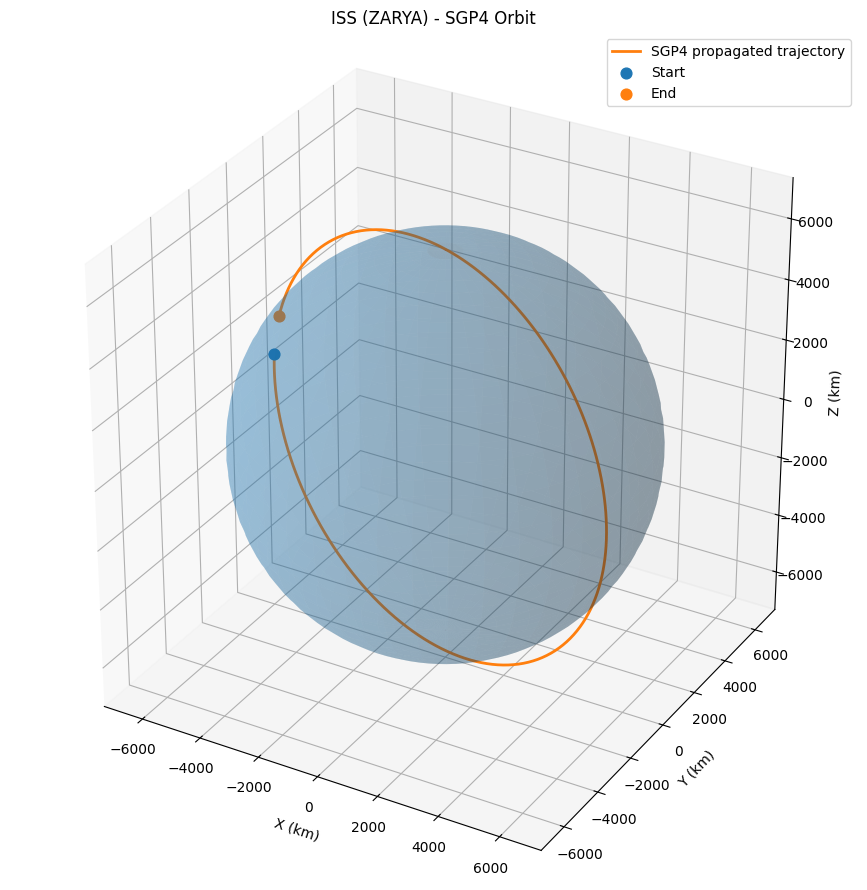

In [8]:
# Dünya'nın ortalama ölçekli referans küresi
R_EARTH_KM = 6378.137

fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection="3d")

# Dünya küresi
u = np.linspace(0, 2 * np.pi, 80)
v = np.linspace(0, np.pi, 40)

earth_x = R_EARTH_KM * np.outer(np.cos(u), np.sin(v))
earth_y = R_EARTH_KM * np.outer(np.sin(u), np.sin(v))
earth_z = R_EARTH_KM * np.outer(np.ones_like(u), np.cos(v))

ax.plot_surface(
    earth_x, earth_y, earth_z,
    alpha=0.25,
    linewidth=0
)

# SGP4 ile hesaplanan uydu yörüngeleri
ax.plot(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    linewidth=2,
    label="SGP4 propagated trajectory"
)

# Başlangıç ve bitiş noktaları
ax.scatter(
    *positions[0],
    s=60,
    label="Start"
)

ax.scatter(
    *positions[-1],
    s=60,
    label="End"
)

# Eksen sınırlarını eşitle: yörünge şeklini çarpıtma
max_range = np.max(np.abs(positions)) * 1.08

ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)
ax.set_box_aspect((1, 1, 1))

ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_zlabel("Z (km)")
ax.set_title(f"{satellite_name} - SGP4 Orbit")
ax.legend()

plt.tight_layout()
plt.show()

In [9]:
!pip -q install skyfield

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 371.1/371.1 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 4.0 MB/s eta 0:00:00


In [10]:
from skyfield.api import EarthSatellite, load, wgs84

# TLE'yi Skyfield uydu nesnesine dönüştür
ts = load.timescale()

sky_satellite = EarthSatellite(
    tle_line1,
    tle_line2,
    satellite_name,
    ts
)

# Skyfield zaman nesnesi
t = ts.from_datetime(now_utc)

# Uydu konumunu hesapla
geocentric = sky_satellite.at(t)

# Dünya yüzeyindeki coğrafi alt nokta
subpoint = wgs84.subpoint(geocentric)

latitude = subpoint.latitude.degrees
longitude = subpoint.longitude.degrees
altitude_km = subpoint.elevation.km

print("Uydu:", satellite_name)
print("Zaman (UTC):", now_utc.isoformat())
print(f"Enlem: {latitude:.5f}°")
print(f"Boylam: {longitude:.5f}°")
print(f"Yükseklik: {altitude_km:.3f} km")

Uydu: ISS (ZARYA)
Zaman (UTC): 2026-10-09T14:04:00.192730+00:00
Enlem: 38.76818°
Boylam: 5.53414°
Yükseklik: 425.349 km


In [12]:
import pandas as pd
from IPython.display import display

mission_control_data = pd.DataFrame({
    "Parameter": [
        "Satellite",
        "Observation time (UTC)",
        "Latitude (deg)",
        "Longitude (deg)",
        "Altitude above ellipsoid (km)",
        "TEME position X (km)",
        "TEME position Y (km)",
        "TEME position Z (km)",
        "TEME speed magnitude (km/s)"
    ],
    "Value": [
        satellite_name,
        now_utc.isoformat(),
        round(latitude, 5),
        round(longitude, 5),
        round(altitude_km, 3),
        round(float(position[0]), 3),
        round(float(position[1]), 3),
        round(float(position[2]), 3),
        round(float(np.linalg.norm(velocity)), 6)
    ]
})

display(mission_control_data)
output_file = "mission_control_satellite_snapshot.csv"

mission_control_data.to_csv(output_file, index=False)

print("Dosya oluşturuldu:", output_file)

from google.colab import files
files.download(output_file)

,Parameter,Value
0,Satellite,ISS (ZARYA)
1,Observation time (UTC),2026-10-09T14:04:00.192730+00:00
2,Latitude (deg),38.76818
3,Longitude (deg),5.53414
4,Altitude above ellipsoid (km),425.349
5,TEME position X (km),-3065.985
6,TEME position Y (km),-4336.79
7,TEME position Z (km),4238.625
8,TEME speed magnitude (km/s),7.660184


Dosya oluşturuldu: mission_control_satellite_snapshot.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
%%html
<div id="app"></div>

<style>
@import url("https://fonts.googleapis.com/css2?family=IBM+Plex+Mono:wght@400;500;600&family=Inter:wght@400;500;600;700&display=swap");

:root {
  font-family: "Inter", sans-serif;
  color: #e6f0ff;
  background: #030711;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
}

* {
  box-sizing: border-box;
}

html,
body,
#app {
  width: 100%;
  height: 600px;
  margin: 0;
  overflow: hidden;
  position: relative;
  background: #030711;
}

#scene {
  position: absolute;
  inset: 0;
  z-index: 0;
}

#scene canvas {
  display: block;
  width: 100%;
  height: 100%;
  touch-action: none;
}

.topbar {
  position: absolute;
  z-index: 2;
  inset: 0 0 auto 0;
  display: flex;
  align-items: center;
  justify-content: space-between;
  padding: 15px 20px;
  background: linear-gradient(
    180deg,
    rgba(3, 7, 17, 0.96),
    rgba(3, 7, 17, 0.45),
    transparent
  );
  pointer-events: none;
}

.eyebrow,
.panel-title,
.footer,
.muted,
.small-line,
.status,
.event-log {
  font-family: "IBM Plex Mono", monospace;
  letter-spacing: 0.06em;
}

.eyebrow {
  color: #69c8ff;
  font-size: 9px;
  margin-bottom: 4px;
}

h1 {
  margin: 0;
  font-size: 18px;
  font-weight: 600;
  letter-spacing: 0.12em;
}

.status {
  display: flex;
  align-items: center;
  gap: 8px;
  font-size: 9px;
  color: #b4c7de;
}

.status-dot {
  width: 7px;
  height: 7px;
  border-radius: 50%;
  background: #54f6a4;
  box-shadow: 0 0 10px rgba(84, 246, 164, 0.8);
}

.panel {
  position: absolute;
  z-index: 2;
  top: 80px;
  width: 220px;
  padding: 12px;
  border: 1px solid rgba(105, 160, 218, 0.2);
  border-radius: 6px;
  background: rgba(5, 13, 27, 0.84);
  backdrop-filter: blur(10px);
}

.left-panel {
  left: 20px;
}

.right-panel {
  right: 20px;
}

.panel-title {
  color: #78bce9;
  font-size: 9px;
  font-weight: 600;
  margin-bottom: 10px;
}

.object-card {
  display: flex;
  align-items: center;
  gap: 10px;
  margin-bottom: 10px;
}

.object-icon {
  display: grid;
  place-items: center;
  width: 36px;
  height: 36px;
  flex: 0 0 auto;
  border: 1px solid rgba(92, 198, 255, 0.6);
  border-radius: 4px;
  color: #8ee0ff;
  background: rgba(40, 119, 180, 0.14);
  font: 600 11px "IBM Plex Mono", monospace;
}

.object-name {
  font-size: 11px;
  font-weight: 600;
}

.muted {
  font-size: 8px;
  color: #7891ae;
}

.divider {
  height: 1px;
  margin: 12px 0;
  background: rgba(122, 163, 205, 0.17);
}

.metric {
  display: flex;
  align-items: center;
  justify-content: space-between;
  gap: 8px;
  margin: 10px 0;
  font-size: 11px;
  color: #93a8c2;
}

.metric strong {
  color: #f1f6ff;
  font: 500 11px "IBM Plex Mono", monospace;
}

.small-line,
.status-row {
  display: flex;
  justify-content: space-between;
  gap: 10px;
  margin: 10px 0;
  font-size: 9px;
  color: #8fa5c0;
}

.small-line strong,
.status-row strong {
  color: #d8e8fa;
  font-weight: 500;
}

.status-row .good {
  color: #69efad;
}

.description {
  font-size: 10px;
  line-height: 1.4;
  color: #9aafc8;
}

.event-log {
  display: flex;
  flex-direction: column;
  gap: 8px;
  color: #8ca6c1;
  font-size: 9px;
}

.event-log div::before {
  content: "> ";
  color: #62d9a1;
}

.footer {
  position: absolute;
  z-index: 2;
  bottom: 0;
  left: 0;
  right: 0;
  display: flex;
  justify-content: space-between;
  padding: 12px 20px;
  background: rgba(3, 7, 17, 0.8);
  color: #69819e;
  font-size: 9px;
  pointer-events: none;
}

.error-message {
  position: absolute;
  z-index: 5;
  left: 50%;
  bottom: 45px;
  transform: translateX(-50%);
  padding: 10px 14px;
  border: 1px solid rgba(255, 151, 105, 0.45);
  border-radius: 4px;
  background: rgba(48, 19, 16, 0.95);
  color: #ffd4c2;
  font-size: 11px;
}

.hidden {
  display: none;
}
</style>

<script type="module">
import * as THREE from "https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.module.js";

const loadScript = (url) => new Promise((resolve, reject) => {
  const script = document.createElement("script");
  script.src = url;
  script.onload = resolve;
  script.onerror = reject;
  document.head.appendChild(script);
});

try {
  await loadScript("https://cdnjs.cloudflare.com/ajax/libs/satellite.js/4.0.0/satellite.min.js");
} catch (err) {
  console.error("satellite.js dynamically load failed:", err);
}

const EARTH_RADIUS_KM = 6378.137;
const EARTH_SCENE_RADIUS = 5;
const SATELLITE_CATALOG_ID = 25544; // ISS

const TLE_URL =
  `https://celestrak.org/NORAD/elements/gp.php?CATNR=${SATELLITE_CATALOG_ID}&FORMAT=TLE`;

const EARTH_TEXTURE_URL =
  "https://svs.gsfc.nasa.gov/vis/a000000/a003600/a003615/flat_earth_Largest_still.0330.jpg";

let satrec = null;
let satelliteName = "International Space Station";
let lastPositionKm = null;
let lastAltitudeKm = 0;
let lastSpeedKmS = 0;
let lastLatitude = 0;
let lastLongitude = 0;
let lastUpdate = "Waiting for data...";

// ---------- UI ----------

document.querySelector("#app").innerHTML = `
  <div id="scene"></div>

  <header class="topbar">
    <div>
      <div class="eyebrow">SPACE SITUATIONAL AWARENESS</div>
      <h1>MISSION CONTROL</h1>
    </div>
    <div class="status">
      <span class="status-dot"></span>
      <span id="connection">CONNECTING TO CELESTRAK</span>
    </div>
  </header>

  <aside class="panel left-panel">
    <div class="panel-title">OBJECT TRACKING</div>
    <div class="object-card">
      <div class="object-icon">ISS</div>
      <div>
        <div class="object-name" id="object-name">ISS (ZARYA)</div>
        <div class="muted">NORAD CAT ID ${SATELLITE_CATALOG_ID}</div>
      </div>
    </div>

    <div class="divider"></div>
    <div class="panel-title">ORBITAL TELEMETRY</div>

    <div class="metric">
      <span>Altitude</span>
      <strong id="altitude">—</strong>
    </div>
    <div class="metric">
      <span>Speed</span>
      <strong id="speed">—</strong>
    </div>
    <div class="metric">
      <span>Latitude</span>
      <strong id="latitude">—</strong>
    </div>
    <div class="metric">
      <span>Longitude</span>
      <strong id="longitude">—</strong>
    </div>
    <div class="metric">
      <span>Earth-centered distance</span>
      <strong id="distance">—</strong>
    </div>

    <div class="divider"></div>
    <div class="panel-title">PROPAGATION</div>
    <div class="small-line">Model <strong>SGP4</strong></div>
    <div class="small-line">Source <strong>CelesTrak TLE</strong></div>
    <div class="small-line">Reference <strong>TEME → geodetic</strong></div>
    <div class="small-line">Updated <strong id="updated">—</strong></div>
  </aside>

  <aside class="panel right-panel">
    <div class="panel-title">MISSION STATUS</div>
    <div class="status-row">
      <span>Orbital propagation</span>
      <strong class="good" id="prop-status">INITIALIZING</strong>
    </div>
    <div class="status-row">
      <span>Data feed</span>
      <strong id="feed-status">PENDING</strong>
    </div>

    <div class="divider"></div>
    <div class="panel-title">REFERENCE FRAME</div>
    <p class="description">
      SGP4 generates a position from TLE data. The position is converted
      to geodetic coordinates for an Earth-fixed globe visualization.
    </p>

    <div class="divider"></div>
    <div class="panel-title">EVENT LOG</div>
    <div id="event-log" class="event-log">
      <div>Awaiting orbital elements...</div>
    </div>
  </aside>

  <footer class="footer">
    <span>LIVE ORBITAL VISUALIZATION</span>
    <span>SIMULATED RENDERING · PUBLIC ORBITAL ELEMENTS</span>
    <span id="clock">UTC —</span>
  </footer>

  <div id="error-message" class="error-message hidden"></div>
`;

// ---------- Three.js scene ----------

const container = document.querySelector("#scene");

const scene = new THREE.Scene();
scene.background = new THREE.Color("#030711");

const camera = new THREE.PerspectiveCamera(
  45,
  container.clientWidth / container.clientHeight,
  0.1,
  1000
);

camera.position.set(0, 7, 15);

const renderer = new THREE.WebGLRenderer({
  antialias: true,
  powerPreference: "high-performance",
});

renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
renderer.setSize(container.clientWidth, container.clientHeight);
renderer.outputColorSpace = THREE.SRGBColorSpace;
container.appendChild(renderer.domElement);

// Mouse drag + wheel controls
let dragging = false;
let previousX = 0;
let previousY = 0;
let cameraAzimuth = 0;
let cameraElevation = 0.35;
let cameraDistance = 15;

renderer.domElement.addEventListener("pointerdown", (event) => {
  dragging = true;
  previousX = event.clientX;
  previousY = event.clientY;
  renderer.domElement.setPointerCapture(event.pointerId);
});

renderer.domElement.addEventListener("pointerup", () => {
  dragging = false;
});

renderer.domElement.addEventListener("pointermove", (event) => {
  if (!dragging) return;

  cameraAzimuth -= (event.clientX - previousX) * 0.005;
  cameraElevation += (event.clientY - previousY) * 0.005;
  cameraElevation = THREE.MathUtils.clamp(cameraElevation, -1.35, 1.35);
  previousX = event.clientX;
  previousY = event.clientY;
});

renderer.domElement.addEventListener("wheel", (event) => {
  cameraDistance += event.deltaY * 0.01;
  cameraDistance = THREE.MathUtils.clamp(cameraDistance, 7, 35);
}, { passive: true });

// Lighting
scene.add(new THREE.AmbientLight(0x9bb6dc, 1.4));
const sunLight = new THREE.DirectionalLight(0xffffff, 2.8);
sunLight.position.set(8, 5, 10);
scene.add(sunLight);

// Starfield
const starPositions = [];
for (let i = 0; i < 1500; i++) {
  const radius = 100;
  const theta = Math.random() * Math.PI * 2;
  const phi = Math.acos(2 * Math.random() - 1);
  starPositions.push(
    radius * Math.sin(phi) * Math.cos(theta),
    radius * Math.cos(phi),
    radius * Math.sin(phi) * Math.sin(theta)
  );
}

const starGeometry = new THREE.BufferGeometry();
starGeometry.setAttribute("position", new THREE.Float32BufferAttribute(starPositions, 3));
const stars = new THREE.Points(starGeometry, new THREE.PointsMaterial({ color: 0xffffff, size: 0.15 }));
scene.add(stars);

// Earth
const earthGeometry = new THREE.SphereGeometry(EARTH_SCENE_RADIUS, 64, 64);
const earthMaterial = new THREE.MeshPhongMaterial({
  color: 0x173e69,
  shininess: 18,
  specular: new THREE.Color(0x315577),
});
const earth = new THREE.Mesh(earthGeometry, earthMaterial);
scene.add(earth);

const textureLoader = new THREE.TextureLoader();
textureLoader.load(EARTH_TEXTURE_URL, (texture) => {
  texture.colorSpace = THREE.SRGBColorSpace;
  earthMaterial.map = texture;
  earthMaterial.color.set(0xffffff);
  earthMaterial.needsUpdate = true;
  addEvent("NASA Earth texture loaded.");
});

// Atmospheric shell
const atmosphere = new THREE.Mesh(
  new THREE.SphereGeometry(EARTH_SCENE_RADIUS * 1.025, 32, 34),
  new THREE.MeshBasicMaterial({
    color: 0x287bd1,
    transparent: true,
    opacity: 0.10,
    side: THREE.BackSide,
  })
);
scene.add(atmosphere);

// Satellite marker
const satelliteMesh = new THREE.Mesh(
  new THREE.SphereGeometry(0.12, 16, 16),
  new THREE.MeshBasicMaterial({ color: 0x80ffb4 })
);
scene.add(satelliteMesh);

const satelliteGlow = new THREE.Mesh(
  new THREE.SphereGeometry(0.22, 16, 16),
  new THREE.MeshBasicMaterial({
    color: 0x30ff9b,
    transparent: true,
    opacity: 0.25,
  })
);
scene.add(satelliteGlow);

// Orbit lines
let orbitLine = null;
const trailGeometry = new THREE.BufferGeometry();
const trailLine = new THREE.Line(trailGeometry, new THREE.LineBasicMaterial({ color: 0x6cf7b2, transparent: true, opacity: 0.9 }));
scene.add(trailLine);

function geodeticToScene(latitudeRad, longitudeRad, altitudeKm) {
  const radius = EARTH_SCENE_RADIUS * (EARTH_RADIUS_KM + altitudeKm) / EARTH_RADIUS_KM;
  const cosLat = Math.cos(latitudeRad);
  return new THREE.Vector3(
    -radius * cosLat * Math.sin(longitudeRad),
    radius * Math.sin(latitudeRad),
    radius * cosLat * Math.cos(longitudeRad)
  );
}

function addEvent(message) {
  const log = document.querySelector("#event-log");
  if (!log) return;
  const row = document.createElement("div");
  row.textContent = `${new Date().toISOString().slice(11, 19)}Z  ${message}`;
  log.prepend(row);
  while (log.children.length > 5) {
    log.removeChild(log.lastElementChild);
  }
}

function showError(message) {
  const el = document.querySelector("#error-message");
  if (!el) return;
  el.textContent = message;
  el.classList.remove("hidden");
}

function updateText(id, value) {
  const el = document.querySelector(`#${id}`);
  if (el) el.textContent = value;
}

function getSatelliteState(date) {
  if (!satrec || !window.satellite) return null;
  const result = window.satellite.propagate(satrec, date);
  const position = result.position;
  const velocity = result.velocity;
  if (!position || !velocity) return null;

  const gmst = window.satellite.gstime(date);
  const geodetic = window.satellite.eciToGeodetic(position, gmst);
  return {
    latitude: window.satellite.degreesLat(geodetic.latitude),
    longitude: window.satellite.degreesLong(geodetic.longitude),
    altitudeKm: geodetic.height,
    speedKmS: Math.sqrt(velocity.x**2 + velocity.y**2 + velocity.z**2),
    positionKm: new THREE.Vector3(position.x, position.y, position.z),
    scenePosition: geodeticToScene(geodetic.latitude, geodetic.longitude, geodetic.height),
  };
}

function buildOrbitLine() {
  if (!satrec) return;
  const points = [];
  const start = new Date();
  for (let seconds = 0; seconds <= 6000; seconds += 40) {
    const date = new Date(start.getTime() + seconds * 1000);
    const state = getSatelliteState(date);
    if (state) points.push(state.scenePosition);
  }
  if (orbitLine) {
    scene.remove(orbitLine);
    orbitLine.geometry.dispose();
  }
  const geometry = new THREE.BufferGeometry().setFromPoints(points);
  orbitLine = new THREE.Line(geometry, new THREE.LineBasicMaterial({ color: 0x42a5ff, transparent: true, opacity: 0.8 }));
  scene.add(orbitLine);
  addEvent(`Orbit path generated: ${points.length} samples.`);
}

async function loadTLE() {
  try {
    updateText("connection", "DOWNLOADING ORBITAL ELEMENTS");
    const response = await fetch(TLE_URL);
    if (!response.ok) throw new Error(`HTTP ${response.status}`);
    const raw = await response.text();
    const lines = raw.split(/\r?\n/).map(l => l.trim()).filter(Boolean);
    const idx = lines.findIndex(l => l.startsWith("1 "));
    if (idx < 0) throw new Error("Invalid TLE format");

    satelliteName = idx > 0 ? lines[idx-1] : "ISS";
    satrec = window.satellite.twoline2satrec(lines[idx], lines[idx+1]);

    updateText("object-name", satelliteName);
    updateText("connection", "CELESTRAK ONLINE");
    updateText("feed-status", "ONLINE");
    updateText("prop-status", "SGP4 READY");
    addEvent("TLE elements loaded.");
    buildOrbitLine();
  } catch (e) {
    // Fallback static TLE
    if (window.satellite) {
      satrec = window.satellite.twoline2satrec(
        "1 25544U 98067A   26281.98258931  .00005946  00000+0  11685-3 0  9991",
        "2 25544  51.6313  96.9458 0006821 239.5445 120.4870 15.48782794589392"
      );
      updateText("connection", "CORS BLOCK - USING CACHED TLE");
      updateText("feed-status", "LOCAL CACHE");
      updateText("prop-status", "SGP4 READY");
      addEvent("CORS limitation; loaded cached ISS TLE.");
      buildOrbitLine();
    }
  }
}

function updateSatellite() {
  const now = new Date();
  const state = getSatelliteState(now);
  if (!state) return;

  satelliteMesh.position.copy(state.scenePosition);
  satelliteGlow.position.copy(state.scenePosition);

  updateText("altitude", `${state.altitudeKm.toFixed(1)} km`);
  updateText("speed", `${state.speedKmS.toFixed(3)} km/s`);
  updateText("latitude", `${state.latitude.toFixed(3)}°`);
  updateText("longitude", `${state.longitude.toFixed(3)}°`);
  updateText("distance", `${state.positionKm.length().toFixed(1)} km`);
  updateText("updated", now.toISOString().slice(11, 19) + " UTC");
  updateText("clock", "UTC " + now.toISOString().slice(11, 19));
}

function animate() {
  requestAnimationFrame(animate);
  camera.position.set(
    cameraDistance * Math.sin(cameraAzimuth) * Math.cos(cameraElevation),
    cameraDistance * Math.sin(cameraElevation),
    cameraDistance * Math.cos(cameraAzimuth) * Math.cos(cameraElevation)
  );
  camera.lookAt(0, 0, 0);
  renderer.render(scene, camera);
}

animate();
await loadTLE();
setInterval(updateSatellite, 1000);
</script>
